# Calibrating the Ward 2022 decks with `skarstrom.calibrate`

The bundled Ward 2022 decks (CO₂ breakthrough on activated carbon at 50, 100 and 200 cm³/min) were calibrated by hand against the digitised outlet CO₂ mole fraction and the thermocouple at z = 0.0715 m (`core/test/papers/ward_2022/README.md`, "Calibration"). This notebook does the same fit with the calibration API, step by step. It is the script `examples/calibrate_ward_2022.py`; the cells below use its helper functions and its **quick** settings (20 cells, forward differences, a budget of 40 runs), so it runs in seconds. Run the script without `--quick` for the full fit, which reproduces the hand calibration.

The fit:

- **cases**: one per flow rate, with the outlet CO₂ and thermocouple datasets that the decks carry;
- **weights**: an uncertainty of 0.03 on each mole fraction and 0.5 K on each temperature (the assumed digitising error), and each dataset's weight equal to its number of points, so every point counts once;
- **shared parameters**: q_s,2 of the CO₂ isotherm and the factor on the paper's dispersion correlation (a user variable that the three decks' dispersion coefficients use); the ambient and wall-end temperature stays at 293 K;
- **per-case parameter**: the inside heat transfer coefficient h_in;
- **start**: the paper's values (q_s,2 6.04 mol/kg, factor 4, h_in 77.5 / 57.9 / 45.2 W/(m² K)).

In [1]:
import sys
sys.path.insert(0, "..")          # examples/: the script and _common.py

import matplotlib.pyplot as plt
import skarstrom as sk
import calibrate_ward_2022 as w

print(sk.__version__)

0.11.1.dev0+g3fed35f


## The cases

`w.case(q, cells)` loads the shipped deck, writes its dispersion coefficient as `dispersion_factor × Eq. 4`, ties the ambient and wall-end temperatures to one variable, and sets the uncertainty and weight of the two datasets. The decks on disk are not changed.

In [2]:
cases = [w.case(q, cells=20) for q in w.FLOWS]
deck = cases[1].sim
print(deck.get_text("layer[1].dispersion_coefficient"))
for name, weight in cases[1].datasets:
    ds = deck.experimental_data[name]
    print(f"{name}: {ds.observable}, {len(ds.x)} points, uncertainty {ds.uncertainty[0]}, weight {weight}")

dispersion_factor * 2.377667005450815e-05
outlet_CO2_mole_fraction[-]_Qin=100[ccm]: Observable('mole_fraction', component='CarbonDioxide', location='top'), 29 points, uncertainty 0.03, weight 29.0
temperature[K]_z=0.0715[m]_Qin=100[ccm]: Observable('temperature', location=0.0715), 37 points, uncertainty 0.5, weight 37.0


## The parameters

In [3]:
params = w.parameters(fit_ambient=False)
for p in params:
    print(p.path, p.lower, p.upper, "shared" if p.shared else "per case", p.start if p.shared else p.case_start)

adsorbent[1].isotherm[CarbonDioxide].m2 5.0 7.0 shared 6.04
variable[dispersion_factor] 1.0 8.0 shared 4.0
layer[1].internal_htc 10.0 500.0 per case [77.5, 57.9, 45.2]


## The fit (quick settings)

In [4]:
result = sk.calibrate(cases, params, differences="forward", max_simulations=40, max_iterations=4)
print(result.table())

parameter                                estimate  std error   rel.     unit    start  bounds     scale
---------------------------------------  --------  ----------  -------  ------  -----  ---------  ------
adsorbent[1].isotherm[CarbonDioxide].m2  5.90266   0.00730703  0.124 %  mol/kg  6.04   5 .. 7     linear
variable[dispersion_factor]              1.52658   0.218781    14.3 %           4      1 .. 8     linear
layer[1].internal_htc [50 ccm]           93.3416   6.14562     6.58 %   W/m2-K  77.5   10 .. 500  linear
layer[1].internal_htc [100 ccm]          78.9407   2.34768     2.97 %   W/m2-K  57.9   10 .. 500  linear
layer[1].internal_htc [200 ccm]          66.2624   1.03305     1.56 %   W/m2-K  45.2   10 .. 500  linear

dataset                                   case     points           rmse       nrmse      max |error|  weight
----------------------------------------  -------  ---------------  ---------  ---------  -----------  ------
outlet_CO2_mole_fraction[-]_Qin=50[ccm]   50 

With the coarse grid the dispersion factor comes out much lower than 3.75: the 20-cell grid adds numerical dispersion of its own, which the factor then does not need to supply. The full fit on the decks' 60 cells gives the hand calibration's values (the script without `--quick`; table below).

In [5]:
sk_table = w.comparison(result)
for label, hand, api in sk_table:
    print(f"{label:26s} hand {hand:14s} API (quick) {api}")

q_s,2 [mol/kg]             hand 5.89 ± 0.01    API (quick) 5.90 ± 0.01
factor on Eq. 4 [-]        hand 3.75 ± 0.12    API (quick) 1.53 ± 0.22
h_in, 50 ccm [W/(m2 K)]    hand 97.3 ± 6.6     API (quick) 93.3 ± 6.1
h_in, 100 ccm [W/(m2 K)]   hand 81.5 ± 2.4     API (quick) 78.9 ± 2.3
h_in, 200 ccm [W/(m2 K)]   hand 69.0 ± 1.1     API (quick) 66.3 ± 1.0


The full fit (`python examples/calibrate_ward_2022.py`, 60 cells, central differences, 177 runs, about 35 s on four cores):

| Value | Hand calibration | `skarstrom.calibrate` |
|---|---|---|
| q_s,2 [mol/kg] | 5.89 ± 0.01 | 5.89 ± 0.01 |
| factor on Eq. 4 | 3.75 ± 0.12 | 3.74 ± 0.12 |
| h_in, 50 ccm [W/(m² K)] | 97.3 ± 6.6 | 96.7 ± 6.7 |
| h_in, 100 ccm [W/(m² K)] | 81.5 ± 2.4 | 81.6 ± 2.4 |
| h_in, 200 ccm [W/(m² K)] | 69.0 ± 1.1 | 69.0 ± 1.1 |

## Overlay and residuals

`result.plot()` shows each dataset with the simulation at the start (dashed) and at the estimate, and the residuals below.

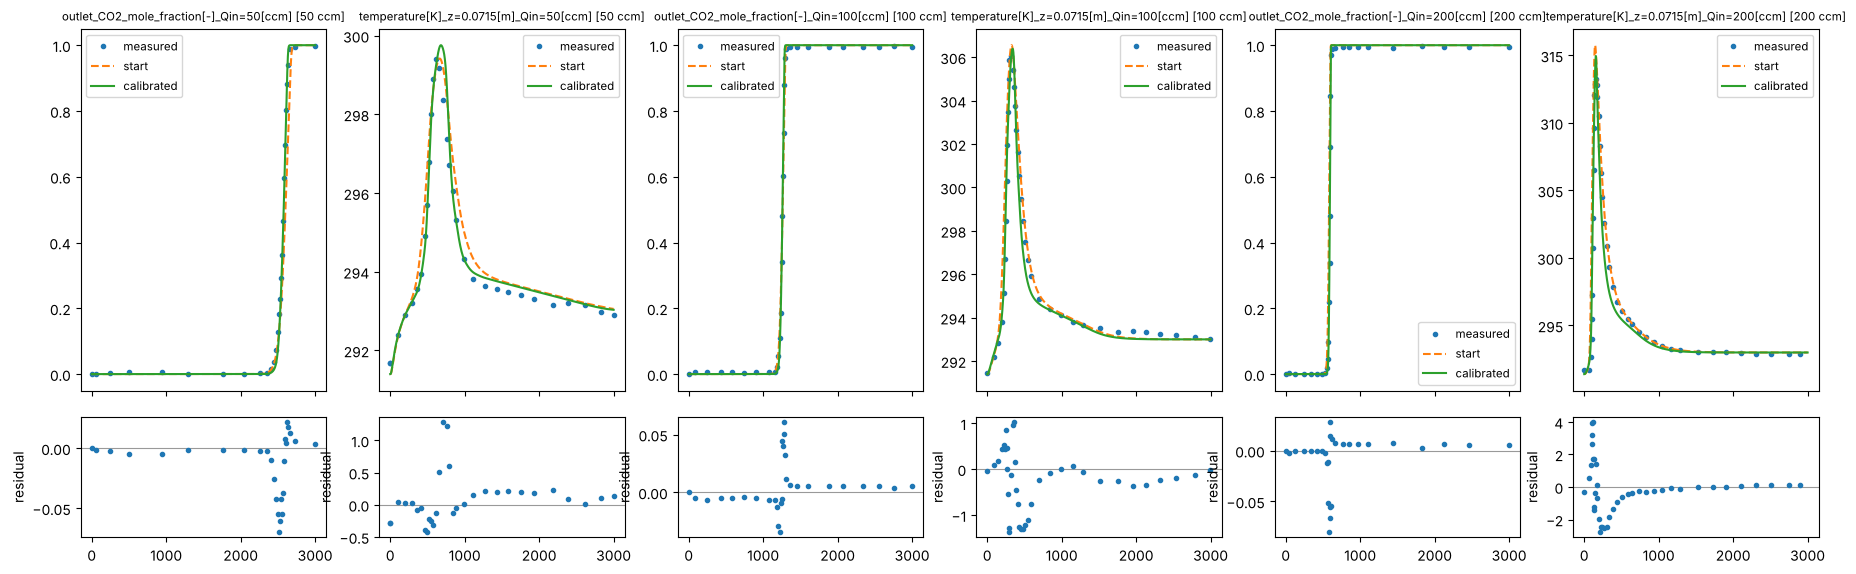

In [6]:
fig = result.plot()
fig.set_size_inches(18, 6)
plt.show()

## The objective and the correlations

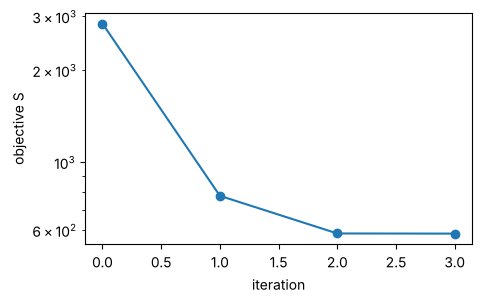

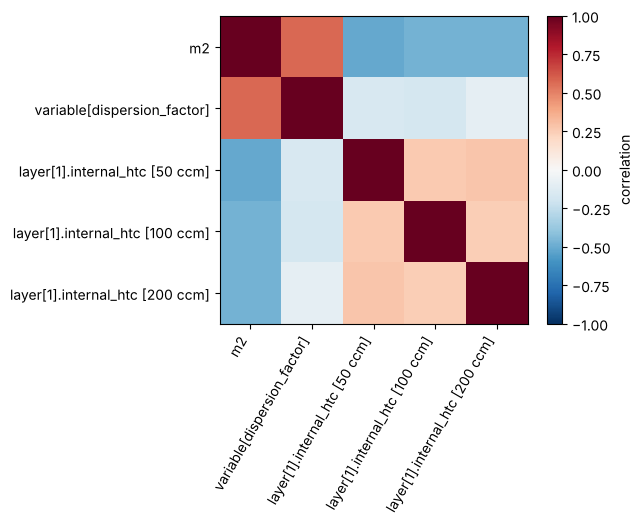

In [7]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(result.objective_trace, "o-")
ax.set(xlabel="iteration", ylabel="objective S")
plt.show()

names = [p.name.replace("adsorbent[1].isotherm[CarbonDioxide].", "") for p in result.parameters]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(result.correlation, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(names)), names, rotation=60, ha="right")
ax.set_yticks(range(len(names)), names)
fig.colorbar(im, label="correlation")
plt.show()

## The calibrated decks

`result.calibrated(i)` is a new Simulation for case `i` with the estimates applied; save it anywhere but over the bundled decks.

In [8]:
import tempfile, pathlib
out = pathlib.Path(tempfile.mkdtemp(prefix="ward2022_calibrated_"))
for i, q in enumerate(w.FLOWS):
    sim = result.calibrated(i)
    sim.save(str(out / f"{w.DECKS[q]}_calibrated.json"))
    print(q, "ccm:", sim.get("layer[1].internal_htc"), "W/(m2 K) ->", out.name)

50 ccm: 93.34163196519498 W/(m2 K) -> ward2022_calibrated_mmfchdiu
100 ccm: 78.9407451549358 W/(m2 K) -> ward2022_calibrated_mmfchdiu
200 ccm: 66.26244531035337 W/(m2 K) -> ward2022_calibrated_mmfchdiu
